### Testing the frequency response of different FLAP filters

In [73]:
import flap
import numpy as np
import matplotlib.pyplot as plt

In [74]:
n_of_samples = int(1e7)

In [75]:
noise_data = np.random.normal(0, 1, n_of_samples)

In [76]:
noise = flap.DataObject(
    noise_data,
    coordinates = flap.Coordinate('Time', start = 0.0, step = 20e-6, dimension_list=[0])
)

[]

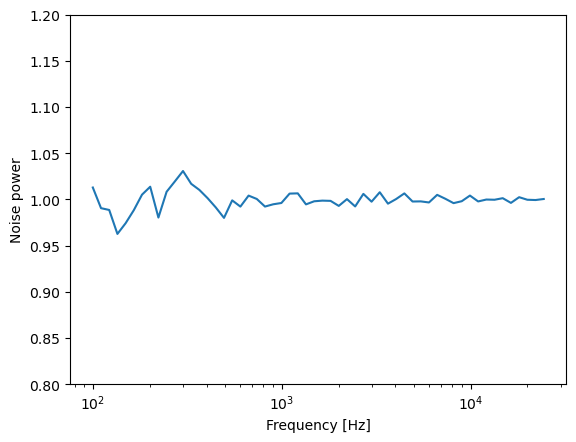

In [81]:
noise_apsd = noise.apsd(coordinate = 'Time')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Noise power')
plt.plot(noise_apsd.coordinate('Frequency')[0], noise_apsd.data)
plt.ylim(0.8, 1.2)
plt.semilogx()

In [93]:
noise_bandpass = noise.filter_data(
    coordinate = 'Time',
    options = {
        'Type': 'Bandpass',
        'f_low': 2e3,
        'f_high': 10e3
    }
)

noise_highpass = noise.filter_data(
    coordinate = 'Time',
    options = {
        'Design': 'Butterworth',
        'Type': 'Highpass',
        'f_low': 500,
        'Steepness': 1,
        'Loss': 1,
        'Attenuation': 40
    }
)

In [94]:
bandpass_apsd = noise_bandpass.apsd(coordinate = 'Time')
highpass_apsd = noise_highpass.apsd(coordinate = 'Time')

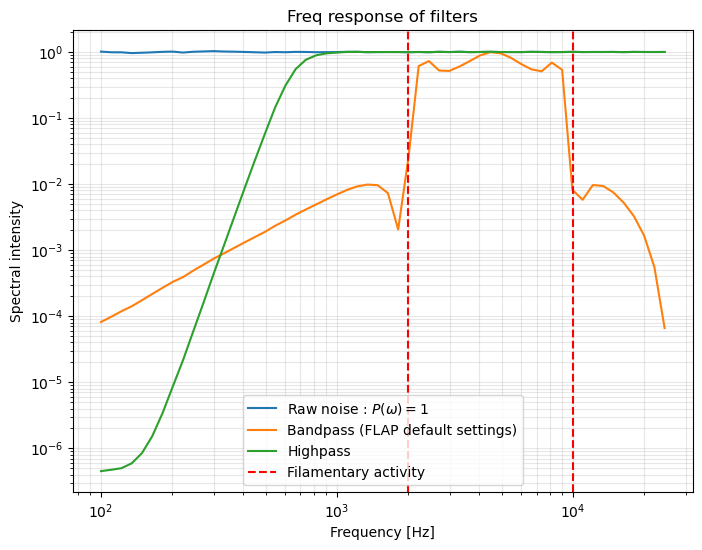

In [106]:
plt.figure(figsize = (8, 6))

plt.xlabel('Frequency [Hz]')
plt.ylabel('Spectral intensity')
plt.plot(noise_apsd.coordinate('Frequency')[0], noise_apsd.data, label = 'Raw noise : $P(\\omega) = 1$')
plt.plot(bandpass_apsd.coordinate('Frequency')[0], bandpass_apsd.data, label = 'Bandpass (FLAP default settings)')
plt.plot(highpass_apsd.coordinate('Frequency')[0], highpass_apsd.data, label = 'Highpass')
plt.loglog()

plt.axvline(2e3, ymax = 1, c = 'r', ls = '--')
plt.axvline(10e3, ymax = 1, c = 'r', ls = '--', label = 'Filamentary activity')


plt.title('Freq response of filters')
plt.legend()
plt.grid(which = 'both', alpha = 0.3)